In [25]:
! pip install -q torch pandas numpy scikit-learn pyarrow optuna matplotlib

In [ ]:
import os, time, json, math, copy, random, warnings, pickle
from dataclasses import dataclass, asdict, replace
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")


DATA_PATH = "../dataset/cleaned_dataset.parquet" 
OUT_DIR = "phase4_results"
os.makedirs(OUT_DIR, exist_ok=True)


QUICK = False #for debugging
QUICK_USERS = 1500
SEEDS = [0, 1, 2, 3, 4]  
EPOCHS = 8 if QUICK else 30


COLD_FRAC = 0.10 # fraction of users held out entirely
COLD_MIN_RATINGS = 30 # cold users need enough ratings to have context + eval rows
COLD_K_LIST = [0, 3, 5, 10, 20]   # number of ratings a cold user "provides"
COLD_K_PRIMARY = 5 # k used inside the decision metric J
N_NEG = 100 # sampled negatives per user for ranking metrics
RANK_USERS = 3000 # users used for sampled-ranking metrics (memory/time)
TOPK, POS_THR = 10, 4 # top-K cutoff, rating >= POS_THR counts as "liked"
WARM_WEIGHT = 0.5 # J = w*warm_rmse + (1-w)*cold_rmse
MIN_DELTA = 0.0005 # minimum improvement to accept a change
CLIP_PREDS = True # clip predictions to [1,5] when computing RMSE/MAE (all models)
SHRINK_B = 0.0 # shrinkage of book mean (0 = plain mean as in Phase II)
SKIP_COLS = ["u_mean_rating", "b_mean_rating", "u_std_rating"]   # inputs of the wide skip

DEVICE = "cpu"
print("device:", DEVICE, "| QUICK:", QUICK)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

device: cpu | QUICK: False


In [ ]:
df = pd.read_parquet(DATA_PATH)
ID_COLS, LABEL, SPLIT = ["user_id", "book_id"], "rating", "split"
USER_STAT = ["u_mean_rating", "u_std_rating", "u_n_train"]
BOOK_STAT = ["b_mean_rating", "b_n_train"]

missing = [c for c in ID_COLS + [LABEL, SPLIT] + USER_STAT + BOOK_STAT if c not in df.columns]
assert not missing, f"Expected columns not found: {missing}. Edit the names in this cell."

df[SPLIT] = df[SPLIT].astype(str).str.lower().map(
    {"train": "train", "val": "val", "valid": "val", "validation": "val", "test": "test"})
assert df[SPLIT].notna().all(), "Unrecognised values in the split column - extend the mapping above."

FEAT = [c for c in df.columns if c not in ID_COLS + [LABEL, SPLIT]]
bad = [c for c in FEAT if not (pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_bool_dtype(df[c]))]
assert not bad, f"Non-numeric feature columns: {bad}"
df[FEAT] = df[FEAT].astype("float32")
assert not df[FEAT].isna().any().any(), "NaNs in features"

def group_of(c):
    if c in USER_STAT: return "user"
    if c in BOOK_STAT: return "bookstat"
    if c.startswith("d2v_"): return "d2v"
    if c.startswith("p_"): return "genre"
    if c.startswith(("language_code_", "format_", "publisher_")): return "onehot"
    return "book_meta"  

print(df.shape, "| features:", len(FEAT))
print(df[SPLIT].value_counts().to_dict())
print(pd.Series([group_of(c) for c in FEAT]).value_counts().to_dict())
if QUICK:
    rng0 = np.random.default_rng(12345)
    keep_users = rng0.choice(df.user_id.unique(), QUICK_USERS, replace=False)
    df = df[df.user_id.isin(keep_users)].reset_index(drop=True)
    print("QUICK subsample:", df.shape)

(962899, 101) | features: 97
{'train': 670109, 'test': 148614, 'val': 144176}
{'onehot': 38, 'd2v': 30, 'book_meta': 14, 'genre': 10, 'user': 3, 'bookstat': 2}


In [ ]:
rng = np.random.default_rng(12345)
uid = {u: i for i, u in enumerate(np.sort(df.user_id.unique()))}
bid = {b: i for i, b in enumerate(np.sort(df.book_id.unique()))}
U = df.user_id.map(uid).values.astype(np.int64)
B = df.book_id.map(bid).values.astype(np.int64)
Y = df[LABEL].values.astype(np.float32)
SPL = df[SPLIT].values
N_USERS, N_BOOKS = len(uid), len(bid)
UNK = N_USERS 
rows_of = {u: g.values for u, g in pd.Series(np.arange(len(U))).groupby(U)}


cnt_u = np.bincount(U, minlength=N_USERS)
elig = np.flatnonzero(cnt_u >= COLD_MIN_RATINGS)
cold_users = np.sort(rng.choice(elig, int(round(COLD_FRAC * N_USERS)), replace=False))
perm = rng.permutation(cold_users); half = len(perm) // 2
COLD_USERS = {"val": np.sort(perm[:half]), "test": np.sort(perm[half:])}
is_cold_user = np.zeros(N_USERS, bool); is_cold_user[cold_users] = True
IS_COLD = is_cold_user[U]

idx = {s: np.flatnonzero((~IS_COLD) & (SPL == s)) for s in ["train", "val", "test"]}
for s in idx: idx[s] = idx[s][np.argsort(U[idx[s]], kind="stable")]   
print({s: len(v) for s, v in idx.items()}, "| cold users:", {k: len(v) for k, v in COLD_USERS.items()})


tr = idx["train"]; r = Y[tr].astype(np.float64); ui = U[tr]; bi = B[tr]
MU = float(r.mean())
u_cnt = np.bincount(ui, minlength=N_USERS).astype(np.float64)
u_sum = np.bincount(ui, r, N_USERS); u_sq = np.bincount(ui, r * r, N_USERS)
b_cnt = np.bincount(bi, minlength=N_BOOKS).astype(np.float64)
b_sum = np.bincount(bi, r, N_BOOKS)
u_mean = np.where(u_cnt > 0, u_sum / np.maximum(u_cnt, 1), MU)
u_std = np.sqrt(np.clip(np.where(u_cnt > 0, u_sq / np.maximum(u_cnt, 1) - u_mean ** 2, 0), 0, None))
U_STD_DEFAULT = float(u_std[u_cnt > 0].mean())
den = b_cnt + SHRINK_B
b_mean = np.where(den > 0, (b_sum + SHRINK_B * MU) / np.maximum(den, 1e-9), MU)

def loo(sum_, cnt_, x, k=0.0): # leave-one-out mean
    d = cnt_ - 1 + k
    return np.where(d > 0, (sum_ - x + k * MU) / np.maximum(d, 1e-9), MU)
u_loo = loo(u_sum[ui], u_cnt[ui], r)
b_loo = loo(b_sum[bi], b_cnt[bi], r, SHRINK_B)

raw_user_tab = np.stack([u_mean, u_std, np.log1p(u_cnt)], 1)
raw_user_tab[u_cnt == 0] = [MU, U_STD_DEFAULT, 0.0]

SC = {} # standardisation fitted on warm train rows 
def _fit(n, x): SC[n] = (float(np.mean(x)), float(np.std(x)) + 1e-8)
_fit("u_mean_rating", u_loo); _fit("u_std_rating", u_std[ui]); _fit("u_n_train", np.log1p(u_cnt[ui]))
_fit("b_mean_rating", b_loo); _fit("b_n_train", np.log1p(b_cnt[bi]))
def z(n, x): m, s = SC[n]; return ((x - m) / s).astype(np.float32)
def std_user(raw): return np.stack([z("u_mean_rating", raw[:, 0]), z("u_std_rating", raw[:, 1]), z("u_n_train", raw[:, 2])], 1)


col_ix = {c: i for i, c in enumerate(FEAT)}
UCOLS = [col_ix[c] for c in USER_STAT]; BCOLS = [col_ix[c] for c in BOOK_STAT]
STATIC = [c for c in FEAT if c not in USER_STAT + BOOK_STAT + ["is_reviewed"]]
first = df.assign(_b=B).drop_duplicates("_b").set_index("_b")[STATIC]
book_X = np.zeros((N_BOOKS, len(FEAT)), np.float32)
book_X[np.ix_(first.index.values, [col_ix[c] for c in STATIC])] = first.values
book_X[:, BCOLS[0]] = z("b_mean_rating", b_mean)
book_X[:, BCOLS[1]] = z("b_n_train", np.log1p(b_cnt))
IS_REV = df["is_reviewed"].values.astype(np.float32) if "is_reviewed" in col_ix else None

USER_TAB = std_user(raw_user_tab)
NEUTRAL = std_user(np.array([[MU, U_STD_DEFAULT, 0.0]]))[0] 

X_all = book_X[B]# [N_rows, F] copy
X_all[:, UCOLS] = USER_TAB[U]
if IS_REV is not None: X_all[:, col_ix["is_reviewed"]] = IS_REV
X_all[tr, UCOLS[0]] = z("u_mean_rating", u_loo) # leave-one-out on training rows
X_all[tr, BCOLS[0]] = z("b_mean_rating", b_loo)
print("X_all", X_all.shape, "| train mean rating MU = %.4f" % MU)

{'train': 592893, 'val': 127553, 'test': 131568} | cold users: {'val': 441, 'test': 441}
X_all (962899, 97) | train mean rating MU = 3.9783


In [ ]:
# sanity check
for c in USER_STAT + BOOK_STAT:
    a = X_all[tr, col_ix[c]]; o = df[c].values[tr]
    print(f"{c:15s} corr with Phase-II column on train rows: {np.corrcoef(a, o)[0, 1]:+.3f}")
for s in ["train", "val", "test"]:
    ii = idx[s]
    print(s, "corr(u_mean, rating) = %+.3f | corr(b_mean, rating) = %+.3f" % (
        np.corrcoef(X_all[ii, UCOLS[0]], Y[ii])[0, 1], np.corrcoef(X_all[ii, BCOLS[0]], Y[ii])[0, 1]))
assert not is_cold_user[U[idx["train"]]].any() and not is_cold_user[U[idx["val"]]].any()
assert not np.isnan(X_all).any()
print("OK: no cold user in warm splits, no NaNs. (Correlations should be similar across the three splits.)")

u_mean_rating   corr with Phase-II column on train rows: +1.000
u_std_rating    corr with Phase-II column on train rows: +1.000
u_n_train       corr with Phase-II column on train rows: +1.000
b_mean_rating   corr with Phase-II column on train rows: +0.981
b_n_train       corr with Phase-II column on train rows: +0.999
train corr(u_mean, rating) = +0.410 | corr(b_mean, rating) = +0.237
val corr(u_mean, rating) = +0.411 | corr(b_mean, rating) = +0.241
test corr(u_mean, rating) = +0.413 | corr(b_mean, rating) = +0.240
OK: no cold user in warm splits, no NaNs. (Correlations should be similar across the three splits.)


In [ ]:
rated = {u: np.unique(B[rw]) for u, rw in rows_of.items()}
ALL_BOOKS = np.arange(N_BOOKS)

def sample_negs(users, seed):
    g = np.random.default_rng(seed); out = np.empty((len(users), N_NEG), np.int64)
    for i, u in enumerate(users):
        out[i] = g.choice(np.setdiff1d(ALL_BOOKS, rated[u]), N_NEG, replace=False)
    return out

class ES: pass

def finish_es(es, users, lens, rk, rk_stats, cold, seed):
    es.users = np.asarray(users); es.lens = np.asarray(lens)
    es.starts = np.concatenate([[0], np.cumsum(es.lens)[:-1]])
    es.slice_of = {u: (s, s + l) for u, s, l in zip(es.users, es.starts, es.lens)}
    es.rank_users = np.asarray(rk)
    nb = sample_negs(es.rank_users, seed)
    es.bn = nb.ravel(); es.ugn = np.repeat(es.rank_users, N_NEG)
    es.Xn = book_X[es.bn]; es.Xn[:, UCOLS] = np.repeat(rk_stats, N_NEG, axis=0)
    es.un = np.full(len(es.bn), UNK, np.int64) if cold else es.ugn.copy()
    return es

def build_warm_es(rows, seed):
    es = ES(); es.X = X_all[rows]; es.u = U[rows].copy(); es.ug = U[rows].copy()
    es.b = B[rows]; es.y = Y[rows]; es.ctx = {}
    users, starts, lens = np.unique(es.ug, return_index=True, return_counts=True)
    rk = np.sort(np.random.default_rng(seed).choice(users, min(RANK_USERS, len(users)), replace=False))
    return finish_es(es, users, lens, rk, USER_TAB[rk], False, seed)

KMAX = max(COLD_K_LIST)
COLD_PERM = {u: rng.permutation(rows_of[u]) for u in cold_users}

def cold_raw(rt):
    k = len(rt)
    if k == 0: return np.array([MU, U_STD_DEFAULT, 0.0])
    return np.array([rt.mean(), rt.std() if k >= 2 else U_STD_DEFAULT, np.log1p(k)])

def build_cold_es(users, k, seed):
    es = ES(); Xs, bs, ys, lens, stats = [], [], [], [], []; es.ctx = {}
    for uu in users:
        p = COLD_PERM[uu]; c, e = p[:k], p[KMAX:]
        st = std_user(cold_raw(Y[c])[None, :])[0]
        x = book_X[B[e]]; x[:, UCOLS] = st
        if IS_REV is not None: x[:, col_ix["is_reviewed"]] = IS_REV[e]
        Xs.append(x); bs.append(B[e]); ys.append(Y[e]); lens.append(len(e)); stats.append(st)
        es.ctx[uu] = B[c][Y[c] >= POS_THR] # "liked" context books
    es.X = np.concatenate(Xs); es.b = np.concatenate(bs); es.y = np.concatenate(ys)
    es.ug = np.repeat(users, lens); es.u = np.full(len(es.ug), UNK, np.int64)
    n = min(RANK_USERS, len(users))
    return finish_es(es, users, lens, users[:n], np.stack(stats)[:n], True, seed)

WARM = {"val": build_warm_es(idx["val"], 1), "test": build_warm_es(idx["test"], 2)}
COLD = {(w, k): build_cold_es(COLD_USERS[w], k, 3 if w == "val" else 4)
        for w in ["val", "test"] for k in COLD_K_LIST}
print("warm val rows:", len(WARM["val"].y), "| cold val rows (per k):", len(COLD[("val", 5)].y),
      "| negatives per user:", N_NEG)


TR_X = torch.from_numpy(X_all[tr]).to(DEVICE)
TR_Y = torch.from_numpy(Y[tr]).to(DEVICE)
TR_U = torch.from_numpy(U[tr]).to(DEVICE)
TR_B = torch.from_numpy(B[tr]).to(DEVICE)
TR_UFULL = torch.from_numpy(USER_TAB[U[tr]]).to(DEVICE)
_, st_, ct_ = np.unique(U[tr], return_index=True, return_counts=True)
RK_START = torch.from_numpy(st_).to(DEVICE); RK_CNT = torch.from_numpy(ct_).float().to(DEVICE)

warm val rows: 127553 | cold val rows (per k): 45635 | negatives per user: 100


In [ ]:
@dataclass
class Cfg:
    name: str = "base"
    kind: str = "hybrid" # hybrid | mf
    drop: tuple = ("is_reviewed",) # feature columns removed
    use_emb: bool = False
    emb_dim: int = 32
    gmf: bool = True # add user*book element-wise product to the input
    id_bias: bool = False # scalar user/book biases
    emb_dropout: float = 0.0
    stat_dropout: float = 0.0
    branched: bool = False
    branch_dim: int = 16
    hidden: tuple = (256, 128, 64)
    dropout: float = 0.1
    norm: str = "batch" # batch | layer | none
    output: str = "linear" # linear | sigmoid
    skip: bool = False
    loss: str = "mse" # mse | huber
    huber_delta: float = 1.0
    rank_lambda: float = 0.0
    rank_users: int = 64
    rank_m: int = 16
    weight_alpha: float = 0.0
    lr: float = 1e-3
    wd: float = 1e-4
    emb_l2: float = 1e-5
    batch: int = 1024
    epochs: int = EPOCHS
    patience: int = 5

def KEEP(cfg): return [i for i, c in enumerate(FEAT) if c not in cfg.drop]

class HybridNet(nn.Module):
    def __init__(self, cfg, cols):
        super().__init__()
        self.cfg, self.cols, self.unk = cfg, list(cols), N_USERS
        for c in USER_STAT: assert c in self.cols, "user statistics must not be dropped"
        self.register_buffer("mu", torch.tensor(MU))
        self.register_buffer("logit0", torch.tensor(math.log((MU - 1) / (5 - MU))))
        self.register_buffer("neutral", torch.tensor(NEUTRAL, dtype=torch.float32))
        self.register_buffer("ucols", torch.tensor([self.cols.index(c) for c in USER_STAT]))
        sk = [self.cols.index(c) for c in SKIP_COLS if c in self.cols]
        self.register_buffer("skip_ix", torch.tensor(sk, dtype=torch.long))
        self.use_emb = cfg.use_emb
        d_in = len(self.cols)
        if cfg.branched:
            groups = {}
            for i, c in enumerate(self.cols): groups.setdefault(group_of(c), []).append(i)
            self.gnames = list(groups)
            for g in self.gnames: self.register_buffer(f"gi_{g}", torch.tensor(groups[g]))
            self.branches = nn.ModuleList([nn.Sequential(nn.Linear(len(groups[g]), cfg.branch_dim), nn.ReLU())
                                           for g in self.gnames])
            d_in = cfg.branch_dim * len(self.gnames)
        if self.use_emb:
            d = cfg.emb_dim
            self.user_emb = nn.Embedding(N_USERS + 1, d); self.book_emb = nn.Embedding(N_BOOKS, d)
            nn.init.normal_(self.user_emb.weight, std=0.05); nn.init.normal_(self.book_emb.weight, std=0.05)
            with torch.no_grad(): self.user_emb.weight[self.unk].zero_()
            d_in += 2 * d + (d if cfg.gmf else 0)
            if cfg.id_bias:
                self.ub = nn.Embedding(N_USERS + 1, 1); self.bb = nn.Embedding(N_BOOKS, 1)
                nn.init.zeros_(self.ub.weight); nn.init.zeros_(self.bb.weight)
        layers, d = [], d_in
        for h in cfg.hidden:
            layers.append(nn.Linear(d, h))
            layers.append(nn.BatchNorm1d(h) if cfg.norm == "batch" else nn.LayerNorm(h) if cfg.norm == "layer" else nn.Identity())
            layers += [nn.ReLU(), nn.Dropout(cfg.dropout)]; d = h
        out = nn.Linear(d, 1); nn.init.zeros_(out.weight); nn.init.zeros_(out.bias)
        self.mlp = nn.Sequential(*layers, out)
        if cfg.skip and len(sk):
            self.wide = nn.Linear(len(sk), 1); nn.init.zeros_(self.wide.weight); nn.init.zeros_(self.wide.bias)

    def _user_vec(self, u, user_vec):
        if user_vec is not None: return user_vec, u
        uu = u
        if self.training and self.cfg.emb_dropout > 0:
            m = torch.rand(u.shape, device=u.device) < self.cfg.emb_dropout
            uu = torch.where(m, torch.full_like(u, self.unk), u)
        return self.user_emb(uu), uu

    def forward(self, x, u, b, user_vec=None, ustat=None):
        cfg = self.cfg
        if ustat is not None:
            x = x.clone(); x[:, self.ucols] = ustat
        elif self.training and cfg.stat_dropout > 0:
            m = torch.rand(x.size(0), device=x.device) < cfg.stat_dropout
            x = x.clone(); x[:, self.ucols] = torch.where(m[:, None], self.neutral.expand(x.size(0), -1), x[:, self.ucols])
        feats = x
        if cfg.branched:
            feats = torch.cat([br(x[:, getattr(self, f"gi_{g}")]) for g, br in zip(self.gnames, self.branches)], 1)
        parts = [feats]
        if self.use_emb:
            ue, uu = self._user_vec(u, user_vec); be = self.book_emb(b)
            parts += [ue, be] + ([ue * be] if cfg.gmf else [])
        z_ = self.mlp(torch.cat(parts, 1)).squeeze(-1)
        if cfg.skip and len(self.skip_ix): z_ = z_ + self.wide(x[:, self.skip_ix]).squeeze(-1)
        if cfg.id_bias and self.use_emb: z_ = z_ + self.ub(uu).squeeze(-1) + self.bb(b).squeeze(-1)
        return self.mu + z_ if cfg.output == "linear" else 1 + 4 * torch.sigmoid(z_ + self.logit0)

    def emb_penalty(self, u, b):
        return (self.user_emb(u).pow(2).sum(1) + self.book_emb(b).pow(2).sum(1)).mean()

class BiasedMF(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg, self.use_emb, self.unk = cfg, True, N_USERS
        d = cfg.emb_dim
        self.register_buffer("mu", torch.tensor(MU))
        self.user_emb = nn.Embedding(N_USERS + 1, d); self.book_emb = nn.Embedding(N_BOOKS, d)
        nn.init.normal_(self.user_emb.weight, std=0.05); nn.init.normal_(self.book_emb.weight, std=0.05)
        with torch.no_grad(): self.user_emb.weight[self.unk].zero_()
        self.ub = nn.Embedding(N_USERS + 1, 1); self.bb = nn.Embedding(N_BOOKS, 1)
        nn.init.zeros_(self.ub.weight); nn.init.zeros_(self.bb.weight)
    def forward(self, x, u, b, user_vec=None, ustat=None):
        uu = u
        if user_vec is None:
            if self.training and self.cfg.emb_dropout > 0:
                m = torch.rand(u.shape, device=u.device) < self.cfg.emb_dropout
                uu = torch.where(m, torch.full_like(u, self.unk), u)
            ue = self.user_emb(uu)
        else: ue = user_vec
        return self.mu + self.ub(uu).squeeze(-1) + self.bb(b).squeeze(-1) + (ue * self.book_emb(b)).sum(-1)
    def emb_penalty(self, u, b):
        return (self.user_emb(u).pow(2).sum(1) + self.book_emb(b).pow(2).sum(1)).mean()

def make_model(cfg, cols):
    return BiasedMF(cfg) if cfg.kind == "mf" else HybridNet(cfg, cols)

In [ ]:
def make_opt(model, cfg):
    emb_names = ("user_emb", "book_emb", "ub", "bb")
    emb = [p for n, p in model.named_parameters() if n.split(".")[0] in emb_names]
    dense = [p for n, p in model.named_parameters() if n.split(".")[0] not in emb_names]
    groups = [{"params": dense, "weight_decay": cfg.wd}]
    if emb: groups.append({"params": emb, "weight_decay": 0.0})   # embeddings use the explicit emb_l2 penalty
    return torch.optim.AdamW(groups, lr=cfg.lr)

def class_weights(cfg):
    if cfg.weight_alpha <= 0: return None
    cls = TR_Y.round().long() - 1
    cnt = torch.bincount(cls, minlength=5).float()
    wc = (cnt.sum() / (5 * cnt.clamp(min=1))) ** cfg.weight_alpha
    w = wc[cls]; return w / w.mean()

def rank_loss(model, kt, cfg):
    R, m = cfg.rank_users, cfg.rank_m
    us = torch.randint(0, len(RK_START), (R,), device=DEVICE)
    off = (torch.rand(R, m, device=DEVICE) * RK_CNT[us][:, None]).long()
    rows = (RK_START[us][:, None] + off).reshape(-1)
    pred = model(TR_X[rows].index_select(1, kt), TR_U[rows], TR_B[rows], ustat=TR_UFULL[rows]).view(R, m)
    yr = TR_Y[rows].view(R, m)
    gap = (yr[:, :, None] - yr[:, None, :]).clamp(min=0)
    diff = pred[:, :, None] - pred[:, None, :]
    return (F.softplus(-diff) * gap).sum() / gap.sum().clamp(min=1.0)

def val_rmse(model, keep):
    es = WARM["val"]
    sp, _ = predict_es(model, es, keep, "default", need_neg=False)
    return float(np.sqrt(((np.clip(sp, 1, 5) - es.y) ** 2).mean()))

def train_model(cfg, seed, verbose=False):
    set_seed(seed)
    keep = KEEP(cfg); cols = [FEAT[i] for i in keep]
    kt = torch.as_tensor(keep, device=DEVICE)
    model = make_model(cfg, cols).to(DEVICE)
    opt = make_opt(model, cfg)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    n, Bsz = TR_Y.numel(), cfg.batch
    w = class_weights(cfg)
    best_v, best_state, best_ep, bad, t0 = 1e9, None, 0, 0, time.time()
    for ep in range(cfg.epochs):
        model.train(); perm = torch.randperm(n, device=DEVICE)
        for s in range(0, n, Bsz):
            ib = perm[s:s + Bsz]
            if ib.numel() < 2: continue
            x = TR_X[ib].index_select(1, kt); y = TR_Y[ib]
            pred = model(x, TR_U[ib], TR_B[ib])
            lv = (pred - y) ** 2 if cfg.loss == "mse" else F.huber_loss(pred, y, delta=cfg.huber_delta, reduction="none")
            if w is not None: lv = lv * w[ib]
            loss = lv.mean()
            if cfg.rank_lambda > 0 and cfg.kind == "hybrid": loss = loss + cfg.rank_lambda * rank_loss(model, kt, cfg)
            if model.use_emb and cfg.emb_l2 > 0: loss = loss + cfg.emb_l2 * model.emb_penalty(TR_U[ib], TR_B[ib])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        v = val_rmse(model, keep); sched.step(v)
        if verbose: print(f"  ep {ep+1:2d} val_rmse {v:.4f}")
        if v < best_v - 1e-5:
            best_v, best_ep, bad = v, ep + 1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= cfg.patience: break
    model.load_state_dict(best_state)
    return model, dict(epochs=ep + 1, best_epoch=best_ep, fit_s=round(time.time() - t0, 1))

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

class SkWrap: # lets sklearn baselines use the same evaluation code
    use_emb = False
    def __init__(self, est, keep): self.est, self.keep = est, np.asarray(keep)
    def predict(self, X): return self.est.predict(X[:, self.keep]).astype(np.float32)
    def eval(self): return self

@torch.no_grad()
def predict_arrays(model, X, u, b, keep, vec_tab=None, ug=None, bs=65536):
    if isinstance(model, SkWrap): return model.predict(X)
    model.eval(); kt = torch.as_tensor(keep, device=DEVICE)
    out = np.empty(len(X), np.float32)
    for s in range(0, len(X), bs):
        sl = slice(s, s + bs)
        x = torch.from_numpy(X[sl]).to(DEVICE).index_select(1, kt)
        uv = vec_tab[torch.from_numpy(ug[sl]).to(DEVICE)] if vec_tab is not None else None
        p = model(x, torch.from_numpy(u[sl]).to(DEVICE), torch.from_numpy(b[sl]).to(DEVICE), user_vec=uv)
        out[sl] = p.float().cpu().numpy()
    return out

@torch.no_grad()
def predict_es(model, es, keep, mode="default", need_neg=True):
    vec_tab = None
    if mode == "foldin": # new-user embedding = mean embedding of the books they liked
        W = model.user_emb.weight.detach().clone()
        for usr, liked in es.ctx.items():
            W[usr] = model.book_emb(torch.as_tensor(liked, device=DEVICE)).mean(0) if len(liked) else W[model.unk]
        vec_tab = W
    sp = predict_arrays(model, es.X, es.u, es.b, keep, vec_tab, es.ug)
    sn = predict_arrays(model, es.Xn, es.un, es.bn, keep, vec_tab, es.ugn) if need_neg else None
    return sp, sn

def ndcg_p3(es, sp, k=TOPK, seed=0):
    g = np.random.default_rng(seed); out = []; disc = 1 / np.log2(np.arange(2, k + 2))
    for s, l in zip(es.starts, es.lens):
        if l < 2: continue
        y, p = es.y[s:s + l], sp[s:s + l]
        o = np.lexsort((g.random(l), -p))[:k]; gain = 2.0 ** y - 1
        out.append((gain[o] * disc[:len(o)]).sum() / (np.sort(gain)[::-1][:k] * disc[:min(k, l)]).sum())
    return float(np.mean(out))

def sampled_rank(es, sp, sn, k=TOPK):
    sn = sn.reshape(len(es.rank_users), N_NEG); hr, nd = [], []
    for i, usr in enumerate(es.rank_users):
        s, e = es.slice_of[usr]; pos = sp[s:e][es.y[s:e] >= POS_THR]
        if len(pos) == 0: continue
        rank = (sn[i][None, :] >= pos[:, None]).sum(1)   
        hit = rank < k; hr.append(hit.mean()); nd.append((hit / np.log2(rank + 2)).mean())
    return dict(hr10=float(np.mean(hr)), ndcg10s=float(np.mean(nd)))

def user_sse(es, sp): return np.add.reduceat((np.clip(sp, 1, 5) - es.y) ** 2, es.starts)

def eval_set_metrics(model, es, keep, mode, rank, light):
    sp, sn = predict_es(model, es, keep, mode, need_neg=rank)
    p = np.clip(sp, 1, 5) if CLIP_PREDS else sp
    e = p - es.y
    r = dict(rmse=float(np.sqrt((e ** 2).mean())), mae=float(np.abs(e).mean()))
    if not light:
        r["ndcg_p3"] = ndcg_p3(es, sp)
        r["brmse"] = float(np.mean([np.sqrt((e[es.y == c] ** 2).mean()) for c in range(1, 6) if (es.y == c).any()]))
        if rank: r.update(sampled_rank(es, sp, sn))
    return r, sp

def evaluate_run(model, keep, which="val", light=False, keep_preds=False):
    kept = [FEAT[i] for i in (model.keep if isinstance(model, SkWrap) else keep)]
    rank_ok = "is_reviewed" not in kept
    out, preds = {}, {}
    es = WARM[which]
    m, sp = eval_set_metrics(model, es, keep, "default", rank_ok and not light, light)
    out.update({f"warm_{a}": v for a, v in m.items()})
    if keep_preds: preds["warm_sse"], preds["warm_n"] = user_sse(es, sp), es.lens
    modes = [("unk", "default")] + ([("foldin", "foldin")] if model.use_emb else [])
    P = COLD_K_PRIMARY; cold_sse = {}
    for k in ([P] if light else COLD_K_LIST):
        es = COLD[(which, k)]
        for tag, mode in modes:
            prim = (k == P)
            m, sp = eval_set_metrics(model, es, keep, mode, rank_ok and prim and not light, light or not prim)
            out[f"cold{k}_{tag}_rmse"] = m["rmse"]
            if "hr10" in m: out[f"cold{k}_{tag}_hr10"], out[f"cold{k}_{tag}_ndcg10s"] = m["hr10"], m["ndcg10s"]
            if prim: cold_sse[tag] = user_sse(es, sp)
    bt = min([t for t, _ in modes], key=lambda t: out[f"cold{P}_{t}_rmse"])
    out["cold_rmse"], out["cold_mode"] = out[f"cold{P}_{bt}_rmse"], bt
    if f"cold{P}_{bt}_hr10" in out:
        out["cold_hr10"], out["cold_ndcg10s"] = out[f"cold{P}_{bt}_hr10"], out[f"cold{P}_{bt}_ndcg10s"]
    out["J"] = WARM_WEIGHT * out["warm_rmse"] + (1 - WARM_WEIGHT) * out["cold_rmse"]
    if keep_preds: preds["cold_sse"], preds["cold_n"] = cold_sse[bt], COLD[(which, P)].lens
    return out, preds

In [ ]:
RES_PATH = os.path.join(OUT_DIR, "results.jsonl")
DATA_SIG = f"quick={QUICK}|cold={COLD_FRAC}|negs={N_NEG}|ranku={RANK_USERS}|kp={COLD_K_PRIMARY}|ww={WARM_WEIGHT}"
CACHE = {}
if os.path.exists(RES_PATH):
    for line in open(RES_PATH):
        row = json.loads(line); CACHE[row["key"]] = row
RESULTS = [r for r in CACHE.values()]
print("loaded cached runs:", len(CACHE))

def run_experiment(cfg, seeds=None, verbose=True):
    rows = []
    for s in (SEEDS if seeds is None else seeds):
        key = f"{DATA_SIG}|{json.dumps(asdict(cfg), sort_keys=True)}|{s}"
        if key in CACHE: rows.append(CACHE[key]); continue
        model, info = train_model(cfg, s)
        m, _ = evaluate_run(model, KEEP(cfg), "val")
        row = dict(key=key, exp=cfg.name, seed=s, **info, **m)
        CACHE[key] = row; RESULTS.append(row); rows.append(row)
        with open(RES_PATH, "a") as f: f.write(json.dumps(row) + "\n")
        if verbose: print(f"  {cfg.name} seed {s}: warm {m['warm_rmse']:.4f} | cold@{COLD_K_PRIMARY} {m['cold_rmse']:.4f} | J {m['J']:.4f} | {info['fit_s']}s")
    return pd.DataFrame(rows)

METRICS = ["warm_rmse", "warm_mae", "warm_ndcg_p3", "warm_brmse", "warm_hr10", "warm_ndcg10s", "cold_rmse", "cold_hr10", "J", "fit_s"]
def table(names):
    d = pd.DataFrame(RESULTS); d = d[d.exp.isin(names)]
    cols = [c for c in METRICS if c in d.columns]
    g = d.groupby("exp")[cols].agg(["mean", "std"]).reindex(names)
    return g.round(4)

def select(names, base, primary="J", higher_better=False, guard=None, min_delta=MIN_DELTA, title=""):
    d = pd.DataFrame(RESULTS); d = d[d.exp.isin(names)]
    m = d.groupby("exp")[[primary] + ([guard[0]] if guard else [])].mean()
    sd = d.groupby("exp")[primary].std().fillna(0)
    sign = -1.0 if higher_better else 1.0
    v = sign * m[primary] # lower is better
    thr = max(min_delta, float(sd[base]))
    rows = []
    for n in names:
        gain = float(v[base] - v[n])
        g_ok = True if (not guard or n == base) else bool(m.loc[n, guard[0]] <= m.loc[base, guard[0]] + guard[1])
        passed = (n != base) and gain > thr and g_ok
        rows.append(dict(exp=n, **{primary: round(float(m.loc[n, primary]), 4)}, std=round(float(sd[n]), 4),
                         gain=round(gain, 4), guard_ok=g_ok, passes=passed))
    tab = pd.DataFrame(rows).set_index("exp"); print(f"[{title}] primary={primary} threshold={thr:.4f}"); print(tab.to_string())
    ok = [n for n in names if tab.loc[n, "passes"]]
    if not ok: return base
    best = min(float(v[n]) for n in ok)
    return next(n for n in ok if float(v[n]) <= best + thr) # simplest  among near-best

current = None 
def V(name, **kw): return replace(current, name=name, **kw)
def run_stage(title, variants, primary="J", higher_better=False, guard=None, min_delta=None):
    global current
    cfgs = {current.name: current, **variants}
    for c in cfgs.values(): run_experiment(c)
    w = select(list(cfgs), current.name, primary, higher_better, guard, min_delta or MIN_DELTA, title)
    print(table(list(cfgs)).to_string())
    current = cfgs[w]; print(f"\n>>> [{title}] carried forward: {current.name}")
    return w

loaded cached runs: 0


In [ ]:
#smoke test
_t = replace(Cfg(name="smoke", use_emb=True, branched=True, rank_lambda=0.1, output="sigmoid", skip=True, emb_dropout=0.2, stat_dropout=0.2), epochs=2)
_m, _i = train_model(_t, 0, verbose=True)
_o, _ = evaluate_run(_m, KEEP(_t), "val")
print(_i); print({k: round(v, 4) if isinstance(v, float) else v for k, v in _o.items()})

  ep  1 val_rmse 0.8560
  ep  2 val_rmse 0.8589
{'epochs': 2, 'best_epoch': 1, 'fit_s': 52.8}
{'warm_rmse': 0.856, 'warm_mae': 0.6731, 'warm_ndcg_p3': 0.8639, 'warm_brmse': 1.2334, 'warm_hr10': 0.2134, 'warm_ndcg10s': 0.1185, 'cold0_unk_rmse': 0.9412, 'cold0_foldin_rmse': 0.9412, 'cold3_unk_rmse': 0.9286, 'cold3_foldin_rmse': 0.931, 'cold5_unk_rmse': 0.899, 'cold5_unk_hr10': 0.191, 'cold5_unk_ndcg10s': 0.1011, 'cold5_foldin_rmse': 0.8994, 'cold5_foldin_hr10': 0.1935, 'cold5_foldin_ndcg10s': 0.1022, 'cold10_unk_rmse': 0.8802, 'cold10_foldin_rmse': 0.8806, 'cold20_unk_rmse': 0.8711, 'cold20_foldin_rmse': 0.872, 'cold_rmse': 0.899, 'cold_mode': 'unk', 'cold_hr10': 0.191, 'cold_ndcg10s': 0.1011, 'J': 0.8775}


In [ ]:
M0  = Cfg(name="M0_phase3_repro", drop=(), hidden=(256, 128, 64), dropout=0.0, norm="none", wd=1e-3, emb_l2=0.0, batch=512)
M0b = replace(M0, name="M0b_no_is_reviewed", drop=("is_reviewed",))
for c in (M0, M0b): run_experiment(c)
print(table([M0.name, M0b.name]).to_string())
current = replace(Cfg(name="M0b_flat_mlp", drop=("is_reviewed",)))
run_experiment(current)
print(table([M0.name, M0b.name, current.name]).to_string())

  M0_phase3_repro seed 0: warm 0.8544 | cold@5 0.9194 | J 0.8869 | 57.6s
  M0_phase3_repro seed 1: warm 0.8542 | cold@5 0.9210 | J 0.8876 | 49.1s
  M0_phase3_repro seed 2: warm 0.8542 | cold@5 0.9194 | J 0.8868 | 65.6s
  M0_phase3_repro seed 3: warm 0.8549 | cold@5 0.9146 | J 0.8847 | 44.6s
  M0_phase3_repro seed 4: warm 0.8545 | cold@5 0.9170 | J 0.8858 | 66.0s
  M0b_no_is_reviewed seed 0: warm 0.8542 | cold@5 0.9151 | J 0.8846 | 60.8s
  M0b_no_is_reviewed seed 1: warm 0.8544 | cold@5 0.9232 | J 0.8888 | 68.0s
  M0b_no_is_reviewed seed 2: warm 0.8550 | cold@5 0.9149 | J 0.8849 | 56.2s
  M0b_no_is_reviewed seed 3: warm 0.8550 | cold@5 0.9255 | J 0.8903 | 62.3s
  M0b_no_is_reviewed seed 4: warm 0.8548 | cold@5 0.9149 | J 0.8848 | 55.2s
                   warm_rmse         warm_mae         warm_ndcg_p3         warm_brmse         warm_hr10         warm_ndcg10s         cold_rmse         cold_hr10             J          fit_s        
                        mean     std     mean     std    

In [37]:
MF_VARIANTS = {f"MF_d{d}_l2{l:g}": Cfg(name=f"MF_d{d}_l2{l:g}", kind="mf", emb_dim=d, emb_l2=l, emb_dropout=0.1, lr=3e-3, wd=0.0, epochs=EPOCHS)
               for d, l in [(32, 1e-3), (32, 1e-2), (32, 1e-1), (64, 1e-2)]}
for c in MF_VARIANTS.values(): run_experiment(c)
print(table(list(MF_VARIANTS)).to_string())
MF_BEST = min(MF_VARIANTS.values(), key=lambda c: np.mean([r["warm_rmse"] for r in RESULTS if r["exp"] == c.name]))
print("best MF:", MF_BEST.name)

  MF_d32_l20.001 seed 0: warm 0.8601 | cold@5 0.9379 | J 0.8990 | 27.7s
  MF_d32_l20.001 seed 1: warm 0.8591 | cold@5 0.9384 | J 0.8988 | 29.5s
  MF_d32_l20.001 seed 2: warm 0.8592 | cold@5 0.9376 | J 0.8984 | 29.6s
  MF_d32_l20.001 seed 3: warm 0.8594 | cold@5 0.9377 | J 0.8986 | 29.3s
  MF_d32_l20.001 seed 4: warm 0.8595 | cold@5 0.9382 | J 0.8989 | 29.4s
  MF_d32_l20.01 seed 0: warm 0.8560 | cold@5 0.9378 | J 0.8969 | 29.5s
  MF_d32_l20.01 seed 1: warm 0.8550 | cold@5 0.9383 | J 0.8966 | 29.4s
  MF_d32_l20.01 seed 2: warm 0.8553 | cold@5 0.9375 | J 0.8964 | 29.3s
  MF_d32_l20.01 seed 3: warm 0.8554 | cold@5 0.9376 | J 0.8965 | 30.1s
  MF_d32_l20.01 seed 4: warm 0.8551 | cold@5 0.9381 | J 0.8966 | 27.0s
  MF_d32_l20.1 seed 0: warm 0.8459 | cold@5 0.9369 | J 0.8914 | 41.7s
  MF_d32_l20.1 seed 1: warm 0.8448 | cold@5 0.9383 | J 0.8915 | 46.2s
  MF_d32_l20.1 seed 2: warm 0.8451 | cold@5 0.9371 | J 0.8911 | 46.3s
  MF_d32_l20.1 seed 3: warm 0.8454 | cold@5 0.9380 | J 0.8917 | 42.0s
  MF_

In [38]:
run_stage("M1", {
    "M1a_sigmoid":      V("M1a_sigmoid", output="sigmoid"),
    "M1b_skip":         V("M1b_skip", skip=True),
    "M1c_sigmoid_skip": V("M1c_sigmoid_skip", output="sigmoid", skip=True),
}, primary="J")

  M1a_sigmoid seed 0: warm 0.8544 | cold@5 0.9219 | J 0.8881 | 131.0s
  M1a_sigmoid seed 1: warm 0.8547 | cold@5 0.9195 | J 0.8871 | 146.5s
  M1a_sigmoid seed 2: warm 0.8543 | cold@5 0.9187 | J 0.8865 | 103.7s
  M1a_sigmoid seed 3: warm 0.8541 | cold@5 0.9150 | J 0.8845 | 126.5s
  M1a_sigmoid seed 4: warm 0.8544 | cold@5 0.9176 | J 0.8860 | 113.2s
  M1b_skip seed 0: warm 0.8543 | cold@5 0.9188 | J 0.8866 | 156.4s
  M1b_skip seed 1: warm 0.8536 | cold@5 0.9235 | J 0.8885 | 128.8s
  M1b_skip seed 2: warm 0.8541 | cold@5 0.9138 | J 0.8840 | 120.8s
  M1b_skip seed 3: warm 0.8537 | cold@5 0.9209 | J 0.8873 | 129.1s
  M1b_skip seed 4: warm 0.8541 | cold@5 0.9149 | J 0.8845 | 98.5s
  M1c_sigmoid_skip seed 0: warm 0.8545 | cold@5 0.9218 | J 0.8881 | 119.6s
  M1c_sigmoid_skip seed 1: warm 0.8537 | cold@5 0.9239 | J 0.8888 | 130.7s
  M1c_sigmoid_skip seed 2: warm 0.8543 | cold@5 0.9175 | J 0.8859 | 116.9s
  M1c_sigmoid_skip seed 3: warm 0.8537 | cold@5 0.9198 | J 0.8867 | 129.7s
  M1c_sigmoid_sk

'M0b_flat_mlp'

In [39]:
run_stage("M2", {f"M2_emb{d}": V(f"M2_emb{d}", use_emb=True, emb_dim=d) for d in (16, 32, 64)}, primary="warm_rmse")

  M2_emb16 seed 0: warm 0.8456 | cold@5 0.9241 | J 0.8849 | 89.9s
  M2_emb16 seed 1: warm 0.8452 | cold@5 0.9242 | J 0.8847 | 85.4s
  M2_emb16 seed 2: warm 0.8456 | cold@5 0.9223 | J 0.8840 | 89.8s
  M2_emb16 seed 3: warm 0.8442 | cold@5 0.9158 | J 0.8800 | 75.5s
  M2_emb16 seed 4: warm 0.8447 | cold@5 0.9139 | J 0.8793 | 79.3s
  M2_emb32 seed 0: warm 0.8428 | cold@5 0.9188 | J 0.8808 | 88.5s
  M2_emb32 seed 1: warm 0.8416 | cold@5 0.9226 | J 0.8821 | 91.5s
  M2_emb32 seed 2: warm 0.8420 | cold@5 0.9090 | J 0.8755 | 91.4s
  M2_emb32 seed 3: warm 0.8438 | cold@5 0.9169 | J 0.8804 | 92.2s
  M2_emb32 seed 4: warm 0.8420 | cold@5 0.9118 | J 0.8769 | 89.7s
  M2_emb64 seed 0: warm 0.8390 | cold@5 0.9142 | J 0.8766 | 116.6s
  M2_emb64 seed 1: warm 0.8417 | cold@5 0.9176 | J 0.8796 | 117.4s
  M2_emb64 seed 2: warm 0.8395 | cold@5 0.9164 | J 0.8780 | 116.6s
  M2_emb64 seed 3: warm 0.8414 | cold@5 0.9138 | J 0.8776 | 116.6s
  M2_emb64 seed 4: warm 0.8404 | cold@5 0.9143 | J 0.8773 | 116.5s
[M2] 

'M2_emb64'

In [40]:
run_stage("M3", {
    "M3a_embdrop0.1":        V("M3a_embdrop0.1", emb_dropout=0.1),
    "M3b_embdrop0.3":        V("M3b_embdrop0.3", emb_dropout=0.3),
    "M3c_embdrop0.5":        V("M3c_embdrop0.5", emb_dropout=0.5),
    "M3d_embdrop0.3_stat0.3": V("M3d_embdrop0.3_stat0.3", emb_dropout=0.3, stat_dropout=0.3),
}, primary="J", guard=("warm_rmse", 0.003))

  M3a_embdrop0.1 seed 0: warm 0.8411 | cold@5 0.9127 | J 0.8769 | 118.2s
  M3a_embdrop0.1 seed 1: warm 0.8415 | cold@5 0.9195 | J 0.8805 | 118.2s
  M3a_embdrop0.1 seed 2: warm 0.8420 | cold@5 0.9145 | J 0.8782 | 113.1s
  M3a_embdrop0.1 seed 3: warm 0.8404 | cold@5 0.9150 | J 0.8777 | 118.5s
  M3a_embdrop0.1 seed 4: warm 0.8411 | cold@5 0.9136 | J 0.8773 | 118.5s
  M3b_embdrop0.3 seed 0: warm 0.8448 | cold@5 0.9128 | J 0.8788 | 114.7s
  M3b_embdrop0.3 seed 1: warm 0.8458 | cold@5 0.9201 | J 0.8829 | 118.8s
  M3b_embdrop0.3 seed 2: warm 0.8455 | cold@5 0.9135 | J 0.8795 | 114.5s
  M3b_embdrop0.3 seed 3: warm 0.8436 | cold@5 0.9147 | J 0.8791 | 117.1s
  M3b_embdrop0.3 seed 4: warm 0.8444 | cold@5 0.9143 | J 0.8793 | 117.2s
  M3c_embdrop0.5 seed 0: warm 0.8491 | cold@5 0.9133 | J 0.8812 | 115.0s
  M3c_embdrop0.5 seed 1: warm 0.8496 | cold@5 0.9182 | J 0.8839 | 118.5s
  M3c_embdrop0.5 seed 2: warm 0.8491 | cold@5 0.9125 | J 0.8808 | 116.9s
  M3c_embdrop0.5 seed 3: warm 0.8472 | cold@5 0.912

'M2_emb64'

In [41]:
run_stage("M4", {"M4_branched": V("M4_branched", branched=True)}, primary="J")

  M4_branched seed 0: warm 0.8435 | cold@5 0.9335 | J 0.8885 | 130.9s
  M4_branched seed 1: warm 0.8470 | cold@5 0.9531 | J 0.9000 | 127.6s
  M4_branched seed 2: warm 0.8463 | cold@5 0.9203 | J 0.8833 | 127.2s
  M4_branched seed 3: warm 0.8482 | cold@5 0.9368 | J 0.8925 | 127.9s
  M4_branched seed 4: warm 0.8483 | cold@5 0.9377 | J 0.8930 | 124.3s
[M4] primary=J threshold=0.0011
                  J     std    gain  guard_ok  passes
exp                                                  
M2_emb64     0.8778  0.0011  0.0000      True   False
M4_branched  0.8915  0.0062 -0.0136      True   False
            warm_rmse         warm_mae         warm_ndcg_p3         warm_brmse         warm_hr10         warm_ndcg10s         cold_rmse         cold_hr10               J           fit_s        
                 mean     std     mean     std         mean     std       mean     std      mean     std         mean     std      mean     std      mean     std    mean     std    mean     std
exp           

'M2_emb64'

In [42]:
run_stage("M5a", {"M5a_huber": V("M5a_huber", loss="huber")}, primary="J")

  M5a_huber seed 0: warm 0.8445 | cold@5 0.9174 | J 0.8810 | 117.2s
  M5a_huber seed 1: warm 0.8425 | cold@5 0.9127 | J 0.8776 | 117.0s
  M5a_huber seed 2: warm 0.8417 | cold@5 0.9162 | J 0.8790 | 114.4s
  M5a_huber seed 3: warm 0.8425 | cold@5 0.9127 | J 0.8776 | 117.9s
  M5a_huber seed 4: warm 0.8449 | cold@5 0.9164 | J 0.8806 | 116.5s
[M5a] primary=J threshold=0.0011
                J     std    gain  guard_ok  passes
exp                                                
M2_emb64   0.8778  0.0011  0.0000      True   False
M5a_huber  0.8792  0.0016 -0.0013      True   False
          warm_rmse         warm_mae         warm_ndcg_p3         warm_brmse         warm_hr10         warm_ndcg10s         cold_rmse         cold_hr10               J           fit_s        
               mean     std     mean     std         mean     std       mean     std      mean     std         mean     std      mean     std      mean     std    mean     std    mean     std
exp                                

'M2_emb64'

In [43]:
run_stage("M5b", {f"M5b_rank{l:g}": V(f"M5b_rank{l:g}", rank_lambda=l) for l in (0.1, 0.3, 1.0)},
          primary="warm_ndcg10s", higher_better=True, guard=("warm_rmse", 0.003), min_delta=0.003)

  M5b_rank0.1 seed 0: warm 0.8433 | cold@5 0.9343 | J 0.8888 | 190.8s
  M5b_rank0.1 seed 1: warm 0.8440 | cold@5 0.9291 | J 0.8865 | 188.7s
  M5b_rank0.1 seed 2: warm 0.8433 | cold@5 0.9197 | J 0.8815 | 191.2s
  M5b_rank0.1 seed 3: warm 0.8450 | cold@5 0.9258 | J 0.8854 | 192.2s
  M5b_rank0.1 seed 4: warm 0.8439 | cold@5 0.9215 | J 0.8827 | 189.9s
  M5b_rank0.3 seed 0: warm 0.8487 | cold@5 0.9127 | J 0.8807 | 162.5s
  M5b_rank0.3 seed 1: warm 0.8498 | cold@5 0.9190 | J 0.8844 | 162.7s
  M5b_rank0.3 seed 2: warm 0.8480 | cold@5 0.9209 | J 0.8844 | 160.9s
  M5b_rank0.3 seed 3: warm 0.8519 | cold@5 0.9330 | J 0.8924 | 163.9s
  M5b_rank0.3 seed 4: warm 0.8498 | cold@5 0.9166 | J 0.8832 | 159.5s
  M5b_rank1 seed 0: warm 0.8560 | cold@5 0.9554 | J 0.9057 | 164.3s
  M5b_rank1 seed 1: warm 0.8578 | cold@5 0.9557 | J 0.9068 | 163.5s
  M5b_rank1 seed 2: warm 0.8570 | cold@5 0.9567 | J 0.9068 | 161.3s
  M5b_rank1 seed 3: warm 0.8651 | cold@5 0.9856 | J 0.9254 | 168.0s
  M5b_rank1 seed 4: warm 0.8

'M2_emb64'

In [44]:
run_stage("M6", {f"M6_w{a:g}": V(f"M6_w{a:g}", weight_alpha=a) for a in (0.25, 0.5)},
          primary="warm_brmse", guard=("warm_rmse", 0.003), min_delta=0.002)
print("\nLadder winner:", current)

  M6_w0.25 seed 0: warm 0.8504 | cold@5 0.9382 | J 0.8943 | 117.7s
  M6_w0.25 seed 1: warm 0.8630 | cold@5 0.9521 | J 0.9076 | 115.5s
  M6_w0.25 seed 2: warm 0.8528 | cold@5 0.9393 | J 0.8961 | 117.4s
  M6_w0.25 seed 3: warm 0.8553 | cold@5 0.9424 | J 0.8988 | 121.8s
  M6_w0.25 seed 4: warm 0.8484 | cold@5 0.9376 | J 0.8930 | 119.9s
  M6_w0.5 seed 0: warm 0.8990 | cold@5 0.9941 | J 0.9465 | 122.2s
  M6_w0.5 seed 1: warm 0.9031 | cold@5 1.0117 | J 0.9574 | 162.1s
  M6_w0.5 seed 2: warm 0.8911 | cold@5 0.9824 | J 0.9367 | 143.4s
  M6_w0.5 seed 3: warm 0.9027 | cold@5 0.9983 | J 0.9505 | 142.2s
  M6_w0.5 seed 4: warm 0.8904 | cold@5 0.9794 | J 0.9349 | 145.6s
[M6] primary=warm_brmse threshold=0.0082
          warm_brmse     std    gain  guard_ok  passes
exp                                                   
M2_emb64      1.2200  0.0082  0.0000      True   False
M6_w0.25      1.1792  0.0104  0.0408     False   False
M6_w0.5       1.1529  0.0154  0.0672     False   False
         warm_rmse 

In [45]:
try:
    import optuna
except ImportError:
    raise ImportError("pip install optuna")
HP_EPOCHS = 6 if QUICK else 20
N_TRIALS = 8 if QUICK else 30
HIDDEN = {"128-64": (128, 64), "256-128-64": (256, 128, 64), "512-256-128": (512, 256, 128), "256-256": (256, 256)}

def cfg_from_params(base, p, name):
    kw = dict(hidden=HIDDEN[p["hidden"]], dropout=p["dropout"], wd=p["wd"], lr=p["lr"], emb_l2=p["emb_l2"], batch=p["batch"])
    if base.use_emb: kw.update(emb_dim=p["emb_dim"], emb_dropout=p["emb_dropout"])
    if base.rank_lambda > 0: kw.update(rank_lambda=p["rank_lambda"])
    return replace(base, name=name, **kw)

HP_BASE = replace(current, epochs=HP_EPOCHS)
def objective(trial):
    p = dict(hidden=trial.suggest_categorical("hidden", list(HIDDEN)),
             dropout=trial.suggest_float("dropout", 0.0, 0.4),
             wd=trial.suggest_float("wd", 1e-6, 1e-2, log=True),
             lr=trial.suggest_float("lr", 3e-4, 5e-3, log=True),
             emb_l2=trial.suggest_float("emb_l2", 1e-7, 1e-3, log=True),
             batch=trial.suggest_categorical("batch", [512, 1024, 2048]))
    if HP_BASE.use_emb:
        p["emb_dim"] = trial.suggest_categorical("emb_dim", [16, 32, 64]); p["emb_dropout"] = trial.suggest_float("emb_dropout", 0.0, 0.5)
    if HP_BASE.rank_lambda > 0: p["rank_lambda"] = trial.suggest_float("rank_lambda", 0.05, 1.0, log=True)
    cfg = cfg_from_params(HP_BASE, p, f"HP_{trial.number}")
    model, _ = train_model(cfg, 0)
    return evaluate_run(model, KEEP(cfg), "val", light=True)[0]["J"]

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0),
                            storage=f"sqlite:///{OUT_DIR}/optuna.db", study_name=f"phase4_{current.name}", load_if_exists=True)
study.optimize(objective, n_trials=max(0, N_TRIALS - len(study.trials)))
print("best J:", study.best_value, study.best_params)

TUNED = cfg_from_params(replace(current, epochs=EPOCHS), study.best_params, "FINAL_tuned")
LADDER_WINNER = current
run_stage("HP", {TUNED.name: TUNED}, primary="J")
FINAL_CFG = current                       # either the tuned config or the untuned ladder winner
print("\nFINAL CONFIG:\n", FINAL_CFG)

[I 2026-11-14 06:57:27,931] A new study created in RDB with name: phase4_M2_emb64
[I 2026-11-14 07:00:26,662] Trial 0 finished with value: 0.8756694793701172 and parameters: {'hidden': '256-128-64', 'dropout': 0.1694619197355619, 'wd': 0.0003833332156156665, 'lr': 0.0010275113826766166, 'emb_l2': 0.0003690557729213759, 'batch': 512, 'emb_dim': 64, 'emb_dropout': 0.03551802909894347}. Best is trial 0 with value: 0.8756694793701172.
[I 2026-11-14 07:03:57,625] Trial 1 finished with value: 0.8815736174583435 and parameters: {'hidden': '512-256-128', 'dropout': 0.3480048592987277, 'wd': 0.008212461922256876, 'lr': 0.002841660216461454, 'emb_l2': 7.013219779945795e-06, 'batch': 512, 'emb_dim': 32, 'emb_dropout': 0.2073309699952618}. Best is trial 0 with value: 0.8756694793701172.
[I 2026-11-14 07:05:58,557] Trial 2 finished with value: 0.8894630968570709 and parameters: {'hidden': '256-128-64', 'dropout': 0.007515920174542057, 'wd': 0.00029548945587266884, 'lr': 0.0016788413144115002, 'emb_

best J: 0.8738311529159546 {'hidden': '256-256', 'dropout': 0.16607778079188856, 'wd': 8.020763098561638e-06, 'lr': 0.002020584494403023, 'emb_l2': 0.000573443453869718, 'batch': 1024, 'emb_dim': 64, 'emb_dropout': 0.017257294051102212}
  FINAL_tuned seed 0: warm 0.8385 | cold@5 0.9092 | J 0.8738 | 125.1s
  FINAL_tuned seed 1: warm 0.8393 | cold@5 0.9179 | J 0.8786 | 126.3s
  FINAL_tuned seed 2: warm 0.8400 | cold@5 0.9153 | J 0.8776 | 122.9s
  FINAL_tuned seed 3: warm 0.8402 | cold@5 0.9255 | J 0.8828 | 124.2s
  FINAL_tuned seed 4: warm 0.8407 | cold@5 0.9163 | J 0.8785 | 125.9s
[HP] primary=J threshold=0.0011
                  J     std    gain  guard_ok  passes
exp                                                  
M2_emb64     0.8778  0.0011  0.0000      True   False
FINAL_tuned  0.8783  0.0032 -0.0005      True   False
            warm_rmse         warm_mae         warm_ndcg_p3         warm_brmse         warm_hr10         warm_ndcg10s         cold_rmse         cold_hr10            

In [46]:
FINAL_ROWS, FINAL_SSE, FINAL_MODELS = [], {}, {}

def run_final(name, fit_fn, seeds):
    pr_list = []
    for s in seeds:
        model, keep, info = fit_fn(s)
        m, pr = evaluate_run(model, keep, "test", keep_preds=True)
        FINAL_ROWS.append(dict(model=name, seed=s, **info, **m)); pr_list.append(pr)
        if s == seeds[0]: FINAL_MODELS[name] = (model, keep)
        print(f"  {name} seed {s}: warm {m['warm_rmse']:.4f} | cold {m['cold_rmse']:.4f}")
    FINAL_SSE[name] = dict(warm=np.mean([p["warm_sse"] for p in pr_list], 0), warm_n=pr_list[0]["warm_n"],
                           cold=np.mean([p["cold_sse"] for p in pr_list], 0), cold_n=pr_list[0]["cold_n"])

def nn_fit(cfg):
    def f(s):
        m, info = train_model(cfg, s); return m, KEEP(cfg), info
    return f
def sk_fit(est_fn, cols):
    def f(s):
        keep = [col_ix[c] for c in cols]
        est = est_fn().fit(X_all[idx["train"]][:, keep], Y[idx["train"]]); return SkWrap(est, keep), keep, {}
    return f

all_feats = [c for c in FEAT if c != "is_reviewed"]
run_final("Global mean", sk_fit(DummyRegressor, ["u_mean_rating"]), [0])
run_final("LinReg (user+book mean)", sk_fit(LinearRegression, ["u_mean_rating", "b_mean_rating"]), [0])
run_final("LinReg (all features)", sk_fit(LinearRegression, all_feats), [0])
run_final("MLP phase III (M0b)", nn_fit(M0b), SEEDS)
run_final("Biased MF", nn_fit(MF_BEST), SEEDS)
run_final("FINAL design", nn_fit(replace(FINAL_CFG, epochs=EPOCHS)), SEEDS)

  Global mean seed 0: warm 0.9776 | cold 0.9792
  LinReg (user+book mean) seed 0: warm 0.8643 | cold 0.9729
  LinReg (all features) seed 0: warm 0.8589 | cold 0.9714
  MLP phase III (M0b) seed 0: warm 0.8528 | cold 0.9519
  MLP phase III (M0b) seed 1: warm 0.8538 | cold 0.9606
  MLP phase III (M0b) seed 2: warm 0.8538 | cold 0.9521
  MLP phase III (M0b) seed 3: warm 0.8537 | cold 0.9725
  MLP phase III (M0b) seed 4: warm 0.8535 | cold 0.9475
  Biased MF seed 0: warm 0.8440 | cold 0.9462
  Biased MF seed 1: warm 0.8445 | cold 0.9474
  Biased MF seed 2: warm 0.8447 | cold 0.9476
  Biased MF seed 3: warm 0.8443 | cold 0.9466
  Biased MF seed 4: warm 0.8442 | cold 0.9475
  FINAL design seed 0: warm 0.8379 | cold 0.9564
  FINAL design seed 1: warm 0.8392 | cold 0.9530
  FINAL design seed 2: warm 0.8378 | cold 0.9560
  FINAL design seed 3: warm 0.8391 | cold 0.9436
  FINAL design seed 4: warm 0.8392 | cold 0.9489


In [47]:
def boot(names, ref, which="warm", Bn=2000, seed=0):
    g = np.random.default_rng(seed)
    n = FINAL_SSE[ref][f"{which}_n"]; nu = len(n)
    ii = g.integers(0, nu, (Bn, nu)); den = n[ii].sum(1)
    r_ref = np.sqrt(FINAL_SSE[ref][which][ii].sum(1) / den)
    rows = []
    for nm in names:
        r = np.sqrt(FINAL_SSE[nm][which][ii].sum(1) / den); d = r - r_ref
        rows.append(dict(model=nm, rmse=np.sqrt(FINAL_SSE[nm][which].sum() / n.sum()),
                         ci_lo=np.percentile(r, 2.5), ci_hi=np.percentile(r, 97.5),
                         delta_vs_ref=d.mean(), d_lo=np.percentile(d, 2.5), d_hi=np.percentile(d, 97.5)))
    return pd.DataFrame(rows).set_index("model").round(4)

fr = pd.DataFrame(FINAL_ROWS)
cols = [c for c in ["warm_rmse", "warm_mae", "warm_ndcg_p3", "warm_hr10", "warm_ndcg10s", "cold_rmse", "cold_hr10", "fit_s"] if c in fr.columns]
order = list(dict.fromkeys(fr.model))
print("== Test metrics (mean +- std over seeds; deterministic models have std NaN/0) ==")
print(fr.groupby("model")[cols].agg(["mean", "std"]).reindex(order).round(4).to_string())
print("\n== Warm test RMSE, bootstrap over users; delta vs 'MLP phase III (M0b)' (negative = better) ==")
print(boot(order, "MLP phase III (M0b)", "warm").to_string())
print(f"\n== Cold test RMSE (k={COLD_K_PRIMARY}), bootstrap over cold users ==")
print(boot(order, "MLP phase III (M0b)", "cold").to_string())
fr.to_csv(os.path.join(OUT_DIR, "final_test_results.csv"), index=False)

== Test metrics (mean +- std over seeds; deterministic models have std NaN/0) ==
                        warm_rmse         warm_mae         warm_ndcg_p3         warm_hr10         warm_ndcg10s         cold_rmse         cold_hr10           fit_s        
                             mean     std     mean     std         mean     std      mean     std         mean     std      mean     std      mean     std    mean     std
model                                                                                                                                                                     
Global mean                0.9776     NaN   0.7425     NaN       0.7896     NaN    0.0000     NaN       0.0000     NaN    0.9792     NaN    0.0000     NaN     NaN     NaN
LinReg (user+book mean)    0.8643     NaN   0.6764     NaN       0.8489     NaN    0.1008     NaN       0.0404     NaN    0.9729     NaN    0.1105     NaN     NaN     NaN
LinReg (all features)      0.8589     NaN   0.6714     NaN      

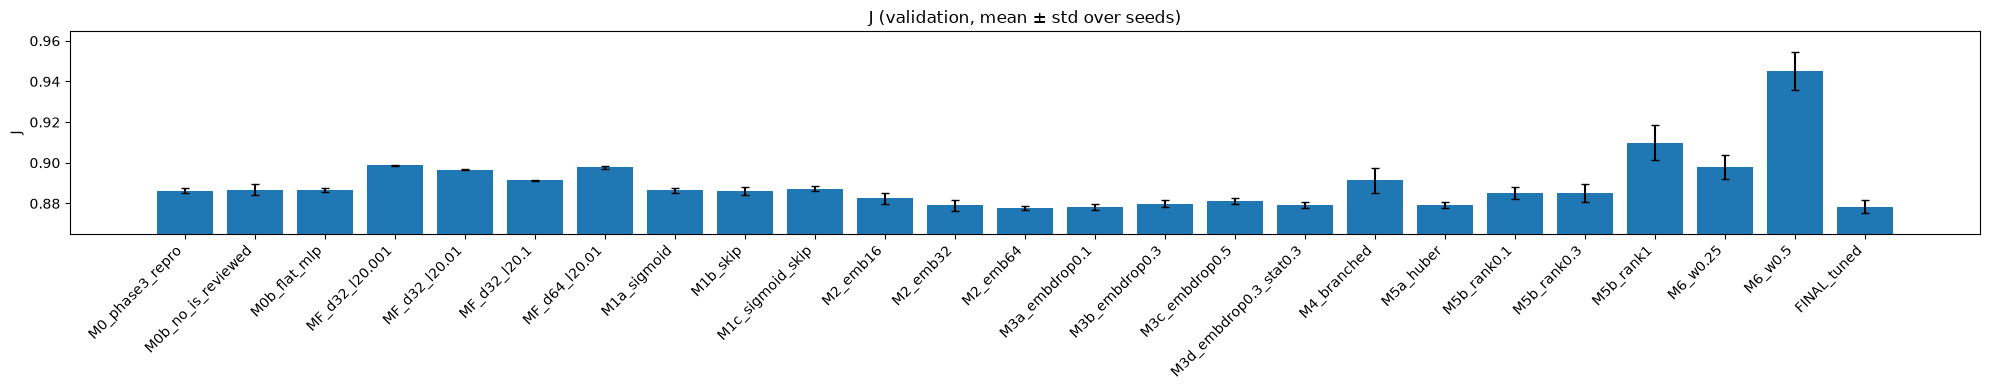

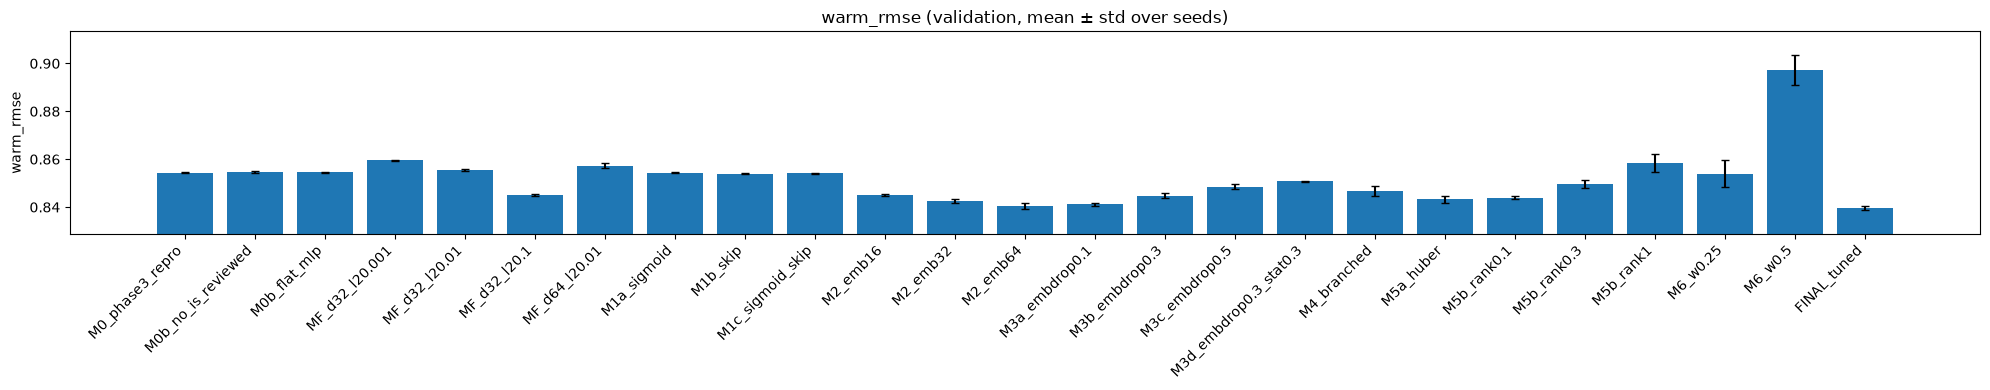

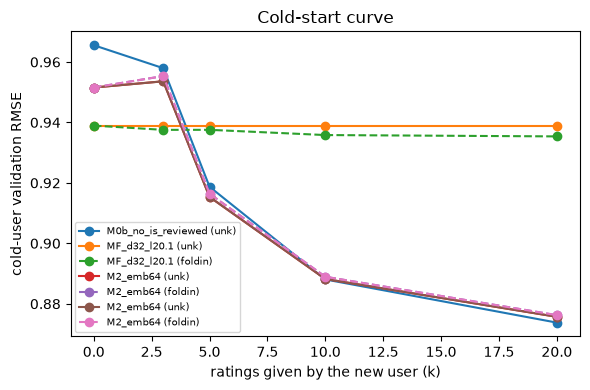

In [48]:
def plot_ladder(names, metric="J", title=None):
    d = pd.DataFrame(RESULTS); d = d[d.exp.isin(names)]
    g = d.groupby("exp")[metric].agg(["mean", "std"]).reindex(names)
    plt.figure(figsize=(max(6, 0.8 * len(names)), 4))
    plt.bar(range(len(names)), g["mean"], yerr=g["std"].fillna(0), capsize=3)
    plt.xticks(range(len(names)), names, rotation=45, ha="right"); plt.ylabel(metric)
    lo, hi = (g["mean"] - g["std"].fillna(0)).min(), (g["mean"] + g["std"].fillna(0)).max()
    plt.ylim(lo - 0.01, hi + 0.01); plt.title(title or f"{metric} (validation, mean ± std over seeds)")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"ladder_{metric}.png"), dpi=150); plt.show()

def plot_cold_curve(names):
    d = pd.DataFrame(RESULTS); plt.figure(figsize=(6, 4))
    for n in names:
        dd = d[d.exp == n]
        for tag, ls in (("unk", "-"), ("foldin", "--")):
            c = [f"cold{k}_{tag}_rmse" for k in COLD_K_LIST]
            if all(x in dd.columns for x in c) and dd[c].notna().all().all():
                plt.plot(COLD_K_LIST, dd[c].mean(), ls, marker="o", label=f"{n} ({tag})")
    plt.xlabel("ratings given by the new user (k)"); plt.ylabel("cold-user validation RMSE")
    plt.legend(fontsize=7); plt.title("Cold-start curve"); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "cold_curve.png"), dpi=150); plt.show()

all_names = list(dict.fromkeys(r["exp"] for r in RESULTS if not r["exp"].startswith("HP_")))
plot_ladder(all_names, "J"); plot_ladder(all_names, "warm_rmse")
plot_cold_curve([M0b.name, MF_BEST.name, LADDER_WINNER.name, FINAL_CFG.name])

In [49]:
model, keep = FINAL_MODELS["FINAL design"]
torch.save(model.state_dict(), os.path.join(OUT_DIR, "final_model.pt"))
with open(os.path.join(OUT_DIR, "final_artifacts.pkl"), "wb") as f:
    pickle.dump(dict(cfg=asdict(FINAL_CFG), feature_names=FEAT, kept_idx=keep, scaler=SC, mu=MU,
                     u_std_default=U_STD_DEFAULT, neutral_user=NEUTRAL, user_ids=uid, book_ids=bid,
                     n_users=N_USERS, n_books=N_BOOKS, unk_index=UNK, user_col_idx=UCOLS, book_col_idx=BCOLS), f)
np.save(os.path.join(OUT_DIR, "book_feature_table.npy"), book_X)
pd.DataFrame(RESULTS).drop(columns=["key"]).to_csv(os.path.join(OUT_DIR, "all_validation_runs.csv"), index=False)
print("saved to", OUT_DIR)

saved to phase4_results


In [50]:
for l in (0.3, 1.0):
    run_experiment(Cfg(name=f"MF_d32_l2{l:g}", kind="mf", emb_dim=32, emb_l2=l, emb_dropout=0.1, lr=3e-3, wd=0.0))
run_experiment(replace(current, name="M2_emb128", emb_dim=128))
print(table(["MF_d32_l20.1","MF_d32_l20.3","MF_d32_l21","M2_emb64","M2_emb128"]).to_string())

  MF_d32_l20.3 seed 0: warm 0.8585 | cold@5 0.9386 | J 0.8985 | 38.4s
  MF_d32_l20.3 seed 1: warm 0.8583 | cold@5 0.9384 | J 0.8984 | 37.6s
  MF_d32_l20.3 seed 2: warm 0.8583 | cold@5 0.9383 | J 0.8983 | 39.2s
  MF_d32_l20.3 seed 3: warm 0.8584 | cold@5 0.9395 | J 0.8990 | 41.3s
  MF_d32_l20.3 seed 4: warm 0.8584 | cold@5 0.9382 | J 0.8983 | 41.4s
  MF_d32_l21 seed 0: warm 0.8585 | cold@5 0.9386 | J 0.8986 | 38.8s
  MF_d32_l21 seed 1: warm 0.8583 | cold@5 0.9384 | J 0.8984 | 45.8s
  MF_d32_l21 seed 2: warm 0.8583 | cold@5 0.9383 | J 0.8983 | 39.4s
  MF_d32_l21 seed 3: warm 0.8584 | cold@5 0.9395 | J 0.8990 | 40.1s
  MF_d32_l21 seed 4: warm 0.8584 | cold@5 0.9382 | J 0.8983 | 41.4s
  M2_emb128 seed 0: warm 0.8383 | cold@5 0.9104 | J 0.8744 | 160.6s
  M2_emb128 seed 1: warm 0.8384 | cold@5 0.9205 | J 0.8794 | 157.1s
  M2_emb128 seed 2: warm 0.8394 | cold@5 0.9178 | J 0.8786 | 162.8s
  M2_emb128 seed 3: warm 0.8386 | cold@5 0.9154 | J 0.8770 | 160.4s
  M2_emb128 seed 4: warm 0.8378 | cold

### [Disclaimer: This notebook wwas generated with the help of Claude Sonnet 5.5]